# 10. Modelos numéricos y búsqueda de configuraciones

Se comparan redes densas (MLP), recurrentes (LSTM) y convolucionales temporales (CNN1D) para pronosticar el precio nacional horario de bolsa. La búsqueda comprende 192 configuraciones y 4800 ajustes, exclusivamente con desarrollo 2000–2021. Las configuraciones se seleccionan mediante el MAE de cinco bloques de validación consecutivos en 2018–2021, con cinco inicializaciones por configuración.

El experimento utiliza únicamente variables numéricas y calendario. Los resultados presentados son de **selección en validación**: el mismo bloque interviene en la parada anticipada y en la comparación de configuraciones. La prueba 2022–2025 no se reevalúa en esta búsqueda. Ese periodo se consultó previamente para otras configuraciones; por tanto, estos resultados no constituyen una nueva evaluación externa ni un benchmark confirmatorio.

## 10.1 Estructura de la entrada y disponibilidad temporal

Para un origen diario $o$ a las 00:00 de Colombia y una longitud de historia $L$, una observación supervisada está formada por

$$
X_o=[\mathbf x_{o-L},\ldots,\mathbf x_{o-1}]\in\mathbb R^{L\times37},\qquad
\mathbf y_o=(y_o,\ldots,y_{o+23})\in\mathbb R^{24}.
$$

El eje temporal conserva frecuencia horaria; la salida predice directamente las 24 horas siguientes. No se realimentan predicciones entre horizontes.

| Bloque predictor | Variables | Columnas | Disponibilidad implementada |
|---|---|---:|---|
| Precio | Precio nacional de bolsa, COP/kWh | 1 | Desplazamiento de 24 horas |
| Demanda | Demanda real y comercial, kWh | 2 | Desplazamiento de 24 horas |
| Meteorología | Temperatura, humedad relativa y precipitación en ocho ciudades | 24 | Desplazamiento de 24 horas |
| Hidrología | Llenado, reserva útil, capacidad útil y aportes diarios | 4 | Dos días desde el inicio del día de referencia; último registro disponible |
| Calendario | Seno y coseno de los ciclos horario, semanal y anual | 6 | Calculados para la fecha de cada fila de entrada |
| **Total** | | **37** | |

Las ciudades son Bogotá, Medellín, Cali, Barranquilla, Cartagena, Bucaramanga, Pereira y Cúcuta. Para una variable horaria $v$, la fila alineada en $s$ contiene $v_{s-24}$. El dato horario más reciente de $X_o$ corresponde a $o-25$ horas; la hidrología se incorpora mediante una unión temporal hacia atrás según su fecha de disponibilidad. Estos rezagos son supuestos retrospectivos, no horarios de publicación certificados. Las variables climáticas proceden de reanálisis y las series pueden incorporar revisiones.

```{figure} _static/modelos-entrada.svg
:alt: Datos numéricos y calendario alineados, ventanas temporales, escalado y salida de 24 precios.
:width: 100%

Construcción de cada ejemplo supervisado. La historia varía entre 24 y 336 horas; las columnas predictoras y el horizonte permanecen constantes.
```

Las entradas se estandarizan por columna con media y desviación estimadas exclusivamente sobre las filas utilizadas por el entrenamiento del fold. El objetivo se divide por su desviación de entrenamiento $s_y>0$, sin centrarlo. Esta transformación permite imponer positividad en unidades originales:

$$
\widetilde y=y/s_y,\qquad
\widehat y=s_y\,\operatorname{Softplus}(z),\qquad
\operatorname{Softplus}(z)=\log(1+e^z).
$$

La restricción supone precios no negativos. Softplus produce valores estrictamente positivos y una derivada sigmoide; no representa exactamente cero. No se aplica sobre un objetivo centrado. La salida tiene 24 componentes porque el horizonte comprende 24 horas, no por una restricción de la arquitectura.

## 10.2 Configuración MLP seleccionada

La variante **M3**, con historia de **24 horas**, transforma $X_o\in\mathbb R^{24\times37}$ en un vector de 888 entradas. Utiliza dos capas ocultas de 256 y 128 unidades, activación ReLU, Dropout de 0,1 después de cada activación, y una proyección a 24 salidas con Softplus. La penalización seleccionada es $\lambda=10^{-3}$.

```{figure} _static/modelos-mlp.svg
:alt: Entrada 24 por 37, aplanamiento a 888, capas densas de 256 y 128, proyección a 24 y Softplus.
:width: 100%

MLP seleccionada. Las dimensiones representan una observación, sin el eje de lote.
```

Con $\mathbf h^{(0)}=\operatorname{vec}(X_o)$, las capas ocultas calculan

$$
\mathbf h^{(\ell)}=D_{0.1}\!\left[\max(0,W_\ell\mathbf h^{(\ell-1)}+\mathbf b_\ell)\right],\qquad \ell\in\{1,2\}.
$$

La salida es $\widehat{\mathbf y}_o=s_y\operatorname{Softplus}(W_3\mathbf h^{(2)}+\mathbf b_3)$. Durante entrenamiento, $D_p(\mathbf h)=\mathbf m\odot\mathbf h/(1-p)$, con máscaras Bernoulli de probabilidad $1-p$; en evaluación actúa como identidad. Las matrices densas permiten interacciones no lineales entre variables y posiciones temporales. El aplanamiento conserva la posición mediante pesos específicos, pero no impone compartición temporal; su número de parámetros crece con $L$.

Esta estructura sigue los fundamentos de las [redes de propagación hacia delante de Goodfellow, Bengio y Courville](https://www.deeplearningbook.org/contents/mlp.html). Los tamaños concretos se seleccionaron dentro del espacio experimental declarado; no corresponden a una reproducción exacta de una arquitectura publicada.

## 10.3 Configuración LSTM seleccionada

La variante **L2** utiliza **72 horas**, una capa LSTM unidireccional de **64 unidades**, el último estado oculto, Dropout de 0,1 y una proyección de 64 a 24 con Softplus. La penalización seleccionada es $\lambda=10^{-3}$. Cada ventana inicia sus estados oculto y de celda en cero; no se transfiere estado entre ejemplos.

```{figure} _static/modelos-lstm.svg
:alt: Secuencia 72 por 37, LSTM de 64 unidades, último estado, Dropout, proyección a 24 y Softplus.
:width: 100%

LSTM seleccionada. La secuencia completa se procesa antes de emitir el horizonte diario.
```

Para el paso temporal $s$, la implementación combina la entrada $\mathbf x_s$, el estado oculto $\mathbf h_{s-1}$ y la memoria $\mathbf c_{s-1}$:

$$
\begin{aligned}
\mathbf i_s&=\sigma(W_{xi}\mathbf x_s+W_{hi}\mathbf h_{s-1}+\mathbf b_i),\\
\mathbf f_s&=\sigma(W_{xf}\mathbf x_s+W_{hf}\mathbf h_{s-1}+\mathbf b_f),\\
\mathbf g_s&=\tanh(W_{xg}\mathbf x_s+W_{hg}\mathbf h_{s-1}+\mathbf b_g),\\
\mathbf o_s&=\sigma(W_{xo}\mathbf x_s+W_{ho}\mathbf h_{s-1}+\mathbf b_o),\\
\mathbf c_s&=\mathbf f_s\odot\mathbf c_{s-1}+\mathbf i_s\odot\mathbf g_s,\\
\mathbf h_s&=\mathbf o_s\odot\tanh(\mathbf c_s).
\end{aligned}
$$

Las compuertas regulan conservación, incorporación y exposición de información. La actualización aditiva de la memoria favorece la propagación de gradientes respecto de una recurrencia puramente multiplicativa, sin garantizar que cualquier dependencia larga pueda aprenderse. La salida usa $\mathbf h_{o-1}$ para los 24 horizontes. Los fundamentos se remontan a [Hochreiter y Schmidhuber (1997)](https://www.bioinf.jku.at/publications/older/2604.pdf); las ecuaciones con compuerta de olvido y las convenciones implementadas corresponden a la [LSTM de PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).

## 10.4 Configuración CNN1D seleccionada

La variante **C3** emplea **24 horas**, dos convoluciones temporales de **64 filtros**, kernel de longitud **5**, paso 1 y padding 2. Cada convolución se sigue de ReLU y Dropout1d de 0,1. Un promedio adaptativo reduce el eje temporal a siete posiciones; el tensor $64\times7$ se aplana a 448 componentes y se proyecta a 24 salidas con Softplus. La penalización seleccionada es $\lambda=10^{-4}$.

```{figure} _static/modelos-cnn.svg
:alt: Entrada 37 por 24, dos convoluciones de 64 filtros, pooling a siete posiciones, aplanamiento y salida positiva de 24 precios.
:width: 100%

CNN1D seleccionada. Se transpone la entrada para que los predictores formen el eje de canales.
```

Cada filtro combina los canales de entrada en un entorno temporal compartiendo parámetros entre posiciones. Con padding cero y kernel 5, una capa calcula la correlación cruzada

$$
z_{c,s}=b_c+\sum_{j=1}^{C_{\mathrm{in}}}\sum_{q=0}^{4}K_{c,j,q}\,h_{j,s+q-2},\qquad h'_{c,s}=\max(0,z_{c,s}).
$$

Las dos capas generan un campo receptivo local de nueve horas antes del pooling. El promedio adaptativo calcula siete promedios sobre intervalos del eje temporal; para 24 posiciones, los intervalos pueden solaparse por el redondeo de sus límites. La capa densa integra después esas representaciones a lo largo de toda la ventana. Dropout1d elimina canales completos durante entrenamiento. El padding simétrico utiliza posiciones de la ventana histórica; no incorpora datos posteriores al origen de pronóstico.

La compartición de filtros reduce la dependencia del número de parámetros respecto de la longitud de entrada y favorece la detección de patrones locales repetidos. El pooling reduce resolución temporal, por lo que puede perder detalle de la hora exacta. Véanse los fundamentos de [redes convolucionales](https://www.deeplearningbook.org/contents/convnets.html) y la [documentación de Conv1d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv1d.html).

## 10.5 Espacio de búsqueda y protocolo de entrenamiento

La búsqueda exhaustiva cruza las siguientes doce arquitecturas con cuatro contextos y cuatro penalizaciones. El Dropout se mantiene en 0,1 en todos los candidatos.

| Familia | Código | Configuración estructural |
|---|---|---|
| MLP | M1 | Densas 64 → 32 |
| MLP | M2 | Densas 128 → 64 |
| MLP | M3 | Densas 256 → 128 |
| MLP | M4 | Densas 128 → 64 → 32 |
| LSTM | L1 | Una capa, 32 unidades |
| LSTM | L2 | Una capa, 64 unidades |
| LSTM | L3 | Dos capas, 32 unidades por capa |
| LSTM | L4 | Una capa de 64 unidades y densa intermedia de 32 |
| CNN1D | C1 | Dos convoluciones, 32 filtros, kernel 5 |
| CNN1D | C2 | Dos convoluciones, 32 filtros, kernel 3 |
| CNN1D | C3 | Dos convoluciones, 64 filtros, kernel 5 |
| CNN1D | C4 | Tres convoluciones, 32 filtros, kernel 3, dilataciones 1, 2 y 4 |

Los contextos son $L\in\{24,72,168,336\}$ horas y Ridge usa $\lambda\in\{0,10^{-5},10^{-4},10^{-3}\}$. El total es $12\times4\times4=192$ configuraciones, con cinco folds y cinco semillas (11037–11041), para **4800 ajustes desde cero**. No se descartan configuraciones según resultados intermedios. Los orígenes admisibles se fijan con la ventana máxima de 336 horas y se comparten entre todas las longitudes. Los cinco bloques consecutivos de validación cubren 2018–2021 y el entrenamiento se amplía antes de cada bloque.

La función objetivo es

$$
\mathcal L(\theta)=\frac{1}{24N}\sum_{i=1}^{N}\sum_{h=0}^{23}\left|\frac{y_{i,h}}{s_y}-\operatorname{Softplus}(z_{i,h})\right|
+\lambda\sum_{W\in\mathcal W}\lVert W\rVert_F^2.
$$

$\mathcal W$ comprende las matrices y tensores de pesos con más de una dimensión; se excluyen sesgos. La suma L2 no se normaliza por la cantidad de parámetros: un mismo $\lambda$ no supone igual regularización efectiva entre arquitecturas. Se utiliza Adam con tasa $10^{-3}$, `weight_decay=0`, lotes de 256 y recorte de la norma del gradiente a 1. Los gradientes se obtienen por retropropagación; en LSTM, a través de la secuencia temporal.

La parada anticipada monitoriza **MAE de validación en COP/kWh, sin penalización**. Una reducción relativa de al menos 0,2 % respecto de la referencia acumulada reinicia la paciencia. Se detiene después de 15 épocas sin esa mejora, con mínimo de 20 y máximo de 200 épocas. Se conservan los pesos de menor MAE absoluto, aunque esa época sea anterior a la 20. El umbral define una meseta práctica; no representa significancia estadística ni el margen de relevancia confirmatorio $\delta$.

Las familias representan hipótesis inductivas diferentes: interacciones densas por posición, memoria recurrente y patrones locales con pesos compartidos. La revisión de textos completos del [capítulo 9](09_literatura.ipynb) verifica LSTM en 7/16 estudios puntuales, MLP/DNN en 6/16 y CNN en 2/16. La selección combina recurrencia y simplicidad con memoria, interacciones por posición y patrones locales. CNN empata en frecuencia con CNN-LSTM y Transformer; su estructura convolucional independiente permite mantener tres referencias diferenciadas. Una referencia describe explícitamente CNN1D y otra no permite confirmar la dimensión. Los tamaños concretos se seleccionaron en desarrollo y constituyen adaptaciones, no réplicas exactas de esos artículos. El capítulo 9 presenta fuentes, configuraciones reportadas, análisis crítico y fórmulas de parámetros y costo. El mismo máximo de épocas no iguala costo computacional ni capacidad. La inferencia confirmatoria con dependencia temporal y el dimensionamiento por potencia permanecen pendientes.


### Preparación temporal y escalado: implementación

Las siguientes funciones construyen las entradas exclusivamente con desarrollo y conservan los controles de disponibilidad y separación temporal.

In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display
import datetime as dt
import hashlib
import json
import numpy as np
import pandas as pd
import re

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
ALLOWED_SOURCES = {'El Tiempo', 'El Espectador', 'Semana', 'Portafolio', 'La República', 'El Colombiano', 'Dinero', 'IDEAM', 'XM'}
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
WEATHER_PREFIXES = ('temperature_2m_c_', 'relative_humidity_2m_pct_', 'precipitation_preceding_hour_mm_')
CITIES = {'bogota', 'medellin', 'cali', 'barranquilla', 'cartagena', 'bucaramanga', 'pereira', 'cucuta'}
NUMERIC_E1 = {TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia'}
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def aware(value):
    parsed = dt.datetime.fromisoformat(value.replace('Z', '+00:00'))
    if parsed.tzinfo is None:
        raise ValueError('Timestamp must have an explicit timezone')
    return parsed

In [4]:
def eligible(record, origin):
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('availability_status') != 'verified_archived_version':
        return False
    if record.get('availability_proof') != 'wayback_payload_digest_and_capture':
        return False
    clean_flag = record.get('quarantined', False) in (False, 0, None, '', '0', 'false', 'False')
    if not re.fullmatch('[0-9a-f]{64}', record.get('version_sha256') or '') or not clean_flag:
        return False
    available = record.get('available_at_verified')
    captured = record.get('capture_at_verified')
    if not available or not captured:
        return False
    return aware(captured) <= aware(available) <= cutoff

In [5]:
def split_train_val_forwardChaining(sequence, numInputs, numOutputs, numJumps):
    """ Returns sets to train and cross-validate a model using forward chaining technique
    
    Parameters:
        sequence (array)  : Full training dataset
        numInputs (int)   : Number of inputs X and Xcv used at each training and validation
        numOutputs (int)  : Number of outputs y and ycv used at each training and validation
        numJumps (int)    : Number of sequence samples to be ignored between (X,y) sets

    Returns:
        X (2D array)    : Array of numInputs arrays used for training
        y (2D array)    : Array of numOutputs arrays used for training
        Xcv (2D array)  : Array of numInputs arrays used for cross-validation
        ycv (2D array)  : Array of numOutputs arrays used for cross-validation
        
    

Fuente: timeseries-cv 0.1.5; licencia original:
MIT License

Copyright (c) 2021 DidierRLopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

The MIT License (MIT)

Copyright (c) 2019 Didier Rodrigues Lopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""
    X, y, Xcv, ycv = (dict(), dict(), dict(), dict())
    j = 2
    while 1:
        start_ix = 0
        end_ix = 0
        startCv_ix = 0
        endCv_ix = 0
        X_it, y_it, Xcv_it, ycv_it = (list(), list(), list(), list())
        i = 0
        while i < j:
            start_ix = numJumps * i
            end_ix = start_ix + numInputs
            seq_x = sequence[start_ix:end_ix]
            X_it.append(seq_x)
            seq_y = sequence[end_ix:end_ix + numOutputs]
            y_it.append(seq_y)
            i += 1
        if end_ix + numInputs + numOutputs > len(sequence):
            break
        startCv_ix = end_ix
        endCv_ix = end_ix + numInputs
        seq_xcv = sequence[startCv_ix:endCv_ix]
        Xcv_it.append(seq_xcv)
        seq_ycv = sequence[endCv_ix:endCv_ix + numOutputs]
        ycv_it.append(seq_ycv)
        X[j - 2] = np.array(X_it)
        y[j - 2] = np.array(y_it)
        Xcv[j - 2] = np.array(Xcv_it)
        ycv[j - 2] = np.array(ycv_it)
        j += 1
    if len(X) == 0 or len(Xcv) == 0:
        print('The sequence provided does not has size enough to populate the return arrays')
    return (X, y, Xcv, ycv)

In [6]:
def validate_development_index(index, config):
    index = pd.DatetimeIndex(index)
    if index.tz is None:
        raise ValueError('El índice debe tener zona horaria.')
    index = index.tz_convert('America/Bogota')
    if len(index) < 2 or not index.is_monotonic_increasing or index.has_duplicates:
        raise ValueError('Índice temporal desordenado, duplicado o insuficiente.')
    if not np.all(np.diff(index.as_unit('ns').asi8) == pd.Timedelta(hours=1).value):
        raise ValueError('El calendario horario contiene huecos.')
    if index[0] < pd.Timestamp(config['development_start']) or index[-1] >= pd.Timestamp(config['development_end_exclusive']):
        raise PermissionError('La preparación sólo admite el periodo de desarrollo.')
    return index

In [7]:
def forward_chaining_folds(index, config, input_usable=None, target_usable=None):
    """Plan temporal por bloques; ventanas supervisadas completas y sin etiquetas compartidas."""
    index = validate_development_index(index, config)
    length = len(index)
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    origins = np.arange(lookback, length - horizon + 1, config['stride_hours'], dtype=np.int64)
    origins = origins[index[origins].hour == 0]
    if input_usable is not None:
        flags = np.asarray(input_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de entradas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins] - bad[origins - lookback] == 0]
    if target_usable is not None:
        flags = np.asarray(target_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de etiquetas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins + horizon] - bad[origins] == 0]
    initial = origins[index[origins] < pd.Timestamp(config['validation_start'])]
    eligible = origins[index[origins] >= pd.Timestamp(config['validation_start'])]
    if len(initial) < 3 or len(eligible) < config['n_splits']:
        raise ValueError('Datos insuficientes para los folds.')
    validation_blocks = np.array_split(eligible, config['n_splits'])
    train_x, train_y, val_x, val_y = split_train_val_forwardChaining(np.arange(config['n_splits'] + 3), 1, 1, 1)
    if len(val_y) != config['n_splits']:
        raise AssertionError('Número inesperado de folds del backend')
    folds = []
    for key in sorted(val_y):
        block = int(val_y[key].ravel()[0])
        block_id = block - 3
        past_blocks = np.unique(np.r_[train_x[key].ravel(), train_y[key].ravel()])
        if past_blocks.max() >= block:
            raise AssertionError('El backend incluyó bloques futuros')
        start = int(validation_blocks[block_id][0])
        stop = int(validation_blocks[block_id + 1][0]) if block_id + 1 < len(validation_blocks) else length
        train = origins[origins + horizon <= start]
        validation = validation_blocks[block_id]
        validation = validation[validation + horizon <= stop]
        if not len(train) or not len(validation):
            raise ValueError('Fold vacío tras la purga de etiquetas')
        assert train[-1] + horizon <= validation[0]
        digest = hashlib.sha256(train.astype('<i8').tobytes() + validation.astype('<i8').tobytes()).hexdigest()
        folds.append(dict(fold=len(folds) + 1, train_origins=train, validation_origins=validation, validation_block=block, indices_sha256=digest))
    return folds

In [8]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [9]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [10]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [11]:
def assert_e1_features(names):
    for name in names:
        if name in NUMERIC_E1:
            continue
        if any((name == prefix + city for prefix in WEATHER_PREFIXES for city in CITIES)):
            continue
        if name in {'hour_sin', 'hour_cos', 'week_sin', 'week_cos', 'year_sin', 'year_cos'}:
            continue
        raise ValueError('E1 sólo admite las variables numéricas declaradas: ' + name)
    return True

In [12]:
def numeric_feature_frame(hourly, hydrology, config):
    index = validate_development_index(hourly.index, config)
    if not hydrology.index.is_monotonic_increasing or hydrology.index.has_duplicates:
        raise ValueError('Índice hidrológico no válido.')
    if hydrology.index.tz is None or (len(hydrology) and hydrology.index[-1] >= pd.Timestamp(config['development_end_exclusive'])):
        raise PermissionError('Hidrología fuera del periodo de desarrollo o sin zona horaria.')
    columns = [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh']
    columns += sorted((c for c in hourly.columns if c.startswith(WEATHER_PREFIXES)))
    features = hourly[columns].shift(config['hourly_release_lag_hours']).copy()
    hydro_columns = ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia']
    released = hydrology[hydro_columns].copy()
    released.index = released.index + pd.Timedelta(days=config['hydrology_release_lag_days'])
    features = features.join(released.reindex(index, method='ffill'))
    if config['include_calendar']:
        phases = {'hour': index.hour / 24, 'week': (index.day_of_week + index.hour / 24) / 7, 'year': (index.day_of_year - 1 + index.hour / 24) / np.where(index.is_leap_year, 366, 365)}
        for name, phase in phases.items():
            features[name + '_sin'] = np.sin(2 * np.pi * phase)
            features[name + '_cos'] = np.cos(2 * np.pi * phase)
    assert_e1_features(features.columns)
    return features

In [13]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [14]:
def build_training_pipeline(config=None, hourly=None, hydrology=None):
    config = pipeline_config(config)
    hourly = load_development_data() if hourly is None else hourly
    hydrology = load_development_data('hydrology') if hydrology is None else hydrology
    features = numeric_feature_frame(hourly, hydrology, config)
    target = hourly[TARGET].copy()
    usable = np.isfinite(features.to_numpy()).all(axis=1)
    folds = forward_chaining_folds(features.index, config, usable, np.isfinite(target.to_numpy()))
    return dict(config=config, features=features, target=target, folds=folds)

In [15]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [16]:
def prepare_fold_arrays(pipeline, fold):
    features = pipeline['features']
    target = pipeline['target'].to_numpy()
    config = pipeline['config']
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    train = fold['train_origins']
    validation = fold['validation_origins']
    train_positions = train[:, None] - lookback + np.arange(lookback)
    validation_positions = validation[:, None] - lookback + np.arange(lookback)
    train_rows = np.unique(train_positions)
    validation_rows = np.unique(validation_positions)
    scaler = StandardScaler().fit(features.iloc[train_rows])
    scaled_train = scaler.transform(features.iloc[train_rows]).astype(np.float32)
    scaled_validation = scaler.transform(features.iloc[validation_rows]).astype(np.float32)
    X_train = scaled_train[np.searchsorted(train_rows, train_positions)]
    X_validation = scaled_validation[np.searchsorted(validation_rows, validation_positions)]
    y_train = target[train[:, None] + np.arange(horizon)].astype(np.float32)
    y_validation = target[validation[:, None] + np.arange(horizon)].astype(np.float32)
    assert features.index[train_rows[-1]] < features.index[validation[0]]
    return dict(fold=fold['fold'], X_train=X_train, y_train=y_train, X_validation=X_validation, y_validation=y_validation, feature_scaler=scaler, feature_names=list(features.columns), train_origins=features.index[train], validation_origins=features.index[validation], scaler_fit_rows=len(train_rows), scaler_fit_start=features.index[train_rows[0]], scaler_fit_end=features.index[train_rows[-1]], target_units='COP/kWh')

## 10.6 Resultados y referencia estacional

Para cada semilla se concatenan los errores de todos los orígenes y las 24 horas de los cinco folds. Se calcula MAE, RMSE y R² sobre esa concatenación; después se promedian las cinco métricas. La desviación estándar refleja variación entre inicializaciones, no incertidumbre temporal. El RMSE se obtiene de errores cuadrados agrupados, no promediando directamente los RMSE de folds.

La referencia estacional repite el precio observado 168 horas antes de cada hora objetivo: $\widehat y^{\mathrm{sem}}_{o+h}=y_{o+h-168}$. Se evalúa sobre los mismos orígenes. La mejora porcentual es $100(1-\operatorname{MAE}_{\mathrm{modelo}}/\operatorname{MAE}_{\mathrm{sem}})$; esta razón no se denomina MASE.


In [17]:
import json
import numpy as np
import pandas as pd
from IPython.display import display
from io import BytesIO
from zipfile import ZipFile
RESULTS = ROOT / 'results/variant_search'
metrics = pd.read_csv(RESULTS / 'metrics.csv')
summary = pd.read_csv(RESULTS / 'summary.csv')
winners = pd.read_csv(RESULTS / 'best_by_family.csv')
assert len(metrics) == 4800 and len(summary) == 192
assert not metrics.duplicated(['candidate', 'fold', 'seed']).any()
assert json.loads((RESULTS / 'completed.json').read_text())['test_evaluated'] is False
pipeline = build_training_pipeline(dict(load_pipeline_config(), lookback_hours=336))
y_all, weekly_all = [], []
for fold in pipeline['folds']:
    positions = fold['validation_origins'][:, None] + np.arange(24)
    y_all.append(pipeline['target'].to_numpy()[positions])
    weekly_all.append(pipeline['target'].to_numpy()[positions - 168])
y_all, weekly_all = np.concatenate(y_all), np.concatenate(weekly_all)
error = weekly_all - y_all
baseline = {'mae': float(np.abs(error).mean()),
            'rmse': float(np.sqrt(np.square(error).mean())),
            'r2': float(1 - np.square(error).sum() / np.square(y_all - y_all.mean()).sum())}
records = [{'Modelo': 'Referencia semanal', 'Configuración': 'Repetición a 168 h',
            'MAE': baseline['mae'], 'DE MAE': np.nan, 'RMSE': baseline['rmse'],
            'R²': baseline['r2'], 'Reducción MAE (%)': 0.0}]
prediction_archive = ZipFile(RESULTS / 'selected_predictions.zip')
for row in winners.itertuples():
    # R² se verifica desde las predicciones de cada semilla, sin abrir prueba.
    r2_values = []
    for seed in range(11037, 11042):
        actual, predicted = [], []
        for fold in range(1, 6):
            folder = RESULTS / 'runs' / row.candidate / f'fold_{fold}_seed_{seed}'
            archive_path = f'{row.candidate}/fold_{fold}_seed_{seed}/predictions.npz'
            with np.load(BytesIO(prediction_archive.read(archive_path))) as saved:
                yy = saved['actual'].astype(np.float64).ravel()
                pp = saved['predictions'].astype(np.float64).ravel()
                actual.append(yy); predicted.append(pp)
        yy, pp = np.concatenate(actual), np.concatenate(predicted)
        r2_values.append(1 - np.square(yy-pp).sum() / np.square(yy-yy.mean()).sum())
    assert np.isclose(np.mean(r2_values), row.r2)
    records.append({'Modelo': row.family, 'Configuración': row.candidate,
                    'MAE': row.mae, 'DE MAE': row.mae_sd, 'RMSE': row.rmse,
                    'R²': row.r2, 'Reducción MAE (%)': 100*(1-row.mae/baseline['mae'])})
prediction_archive.close()
comparison = pd.DataFrame(records)
display(comparison.style.format({'MAE':'{:.3f}', 'DE MAE':'{:.3f}', 'RMSE':'{:.3f}',
                                 'R²':'{:.4f}', 'Reducción MAE (%)':'{:.2f}'}, na_rep='—').hide(axis='index'))


Modelo,Configuración,MAE,DE MAE,RMSE,R²,Reducción MAE (%)
Referencia semanal,Repetición a 168 h,40.157,—,62.444,0.6596,0.00
CNN1D,C3_h24_l2_0.0001,24.155,0.144,37.604,0.8766,39.85
LSTM,L2_h72_l2_0.001,24.624,0.101,37.773,0.8755,38.68
MLP,M3_h24_l2_0.001,24.992,0.095,37.953,0.8743,37.76


### Capacidad y comportamiento de la parada

Las épocas óptimas pueden preceder al mínimo de 20: ese mínimo restringe cuándo se detiene el ajuste, no qué checkpoint se conserva. Los conteos incluyen pesos y sesgos entrenables.

In [18]:
rows = []
for w in winners.itertuples():
    g = metrics[metrics.candidate == w.candidate]
    rows.append({'Modelo':w.family, 'Parámetros':int(g.parameters.iloc[0]),
                 'Mejor época (mediana)':g.best_epoch.median(),
                 'Época de parada (mediana)':g.epochs.median(),
                 'Ajustes':len(g)})
display(pd.DataFrame(rows).style.format(precision=0).hide(axis='index'))
assert (metrics.stop_reason == 'patience').all()
display(pd.DataFrame([{'Ajustes completos':len(metrics), 'Configuraciones':len(summary),
                       'Épocas promedio':metrics.epochs.mean(), 'Máximo observado':metrics.epochs.max(),
                       'Duración (horas)':json.loads((RESULTS/'completed.json').read_text())['total_seconds']/3600}]).style.format(precision=2).hide(axis='index'))

Modelo,Parámetros,Mejor época (mediana),Época de parada (mediana),Ajustes
CNN1D,43224,23,38,25
LSTM,27928,22,36,25
MLP,263576,18,33,25


Ajustes completos,Configuraciones,Épocas promedio,Máximo observado,Duración (horas)
4800,192,35.98,125,11.33


### Comparación con la referencia semanal

Las barras muestran el MAE agrupado y las líneas de error, la desviación estándar entre semillas; no representan intervalos de confianza temporal.

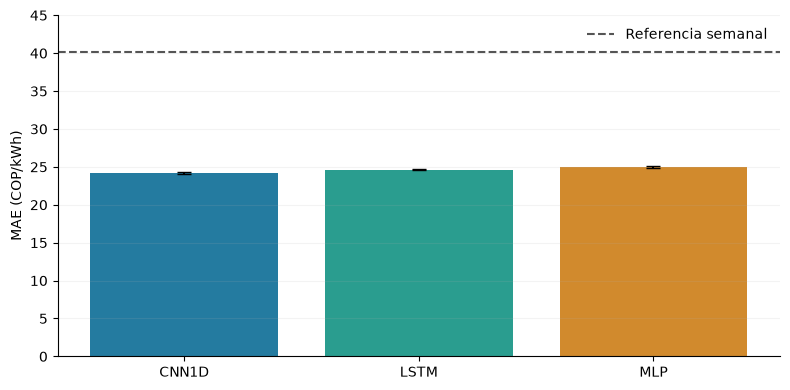

In [19]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(winners))
ax.bar(positions, winners.mae, yerr=winners.mae_sd, capsize=5,
       color=['#247ba0','#2a9d8f','#d18a2d'])
ax.axhline(baseline['mae'], color='#555555', linestyle='--', label='Referencia semanal')
ax.set_xticks(positions, winners.family)
ax.set_ylabel('MAE (COP/kWh)'); ax.set_ylim(0, 45)
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=.15); fig.tight_layout(); plt.show()

### Curvas de aprendizaje de los candidatos seleccionados

Se presentan las ejecuciones del quinto fold y semilla 11037, con MAE de entrenamiento y validación. La línea vertical identifica el checkpoint óptimo; la última época corresponde a la parada. Las curvas de entrenamiento agregan lotes con pesos y máscaras Dropout cambiantes; no son una evaluación final del conjunto de entrenamiento.

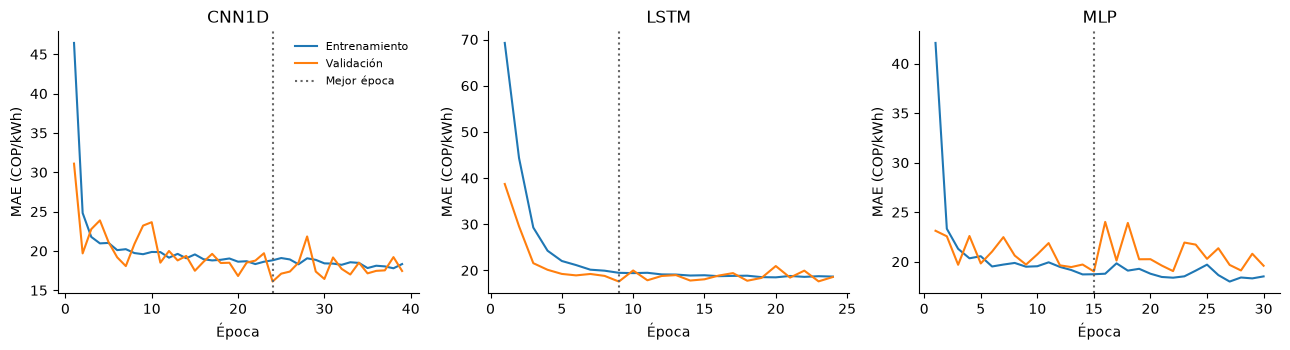

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, w in zip(axes, winners.itertuples()):
    curve = pd.read_csv(RESULTS/'runs'/w.candidate/'fold_5_seed_11037'/'curves.csv')
    row = metrics[(metrics.candidate==w.candidate)&(metrics.fold==5)&(metrics.seed==11037)].iloc[0]
    ax.plot(curve.epoch,curve.train_mae_cop_kwh,label='Entrenamiento')
    ax.plot(curve.epoch,curve.validation_mae_cop_kwh,label='Validación')
    ax.axvline(row.best_epoch,color='#666666',linestyle=':',label='Mejor época')
    ax.set_title(w.family); ax.set_xlabel('Época'); ax.set_ylabel('MAE (COP/kWh)')
    ax.spines[['top','right']].set_visible(False)
axes[0].legend(frameon=False,fontsize=8)
fig.tight_layout(); plt.show()

La configuración C3 con 24 horas de historia y $\lambda=10^{-4}$ presenta el menor MAE medio de selección. La reducción respecto de la referencia semanal es cercana al 40 %. Las diferencias entre los mejores candidatos de las tres familias son menores que la diferencia frente a la referencia, pero no se ha contrastado su significancia con un procedimiento que considere dependencia temporal y selección múltiple.

Los contextos de 24 y 72 horas concentran las mejores configuraciones por familia. Esto no demuestra ausencia de información útil en historias más largas: capacidad, regularización, optimización y representación temporal se modifican conjuntamente. La positividad de salida y el procedimiento de parada también difieren del piloto inicial de 30 épocas, por lo que el cambio de error no puede atribuirse a un único factor.

Los 4800 ajustes terminaron por paciencia y ninguno alcanzó el máximo de 200 épocas. Las curvas ilustrativas permiten examinar mejoras iniciales y estabilización, pero el umbral del 0,2 % no es un contraste de hipótesis. El uso de validación tanto para elegir la época como para seleccionar entre 192 candidatos introduce optimismo. Estos valores no deben presentarse como errores de prueba de los nuevos modelos.

## 10.7 Alcance de la evaluación

La búsqueda utiliza datos retrospectivos y rezagos de disponibilidad supuestos. Las variables meteorológicas urbanas no representan directamente las cuencas aportantes; la correlación entre predictores dificulta atribuir su contribución individual. El análisis de importancia de los modelos iniciales no se transfiere automáticamente a estas nuevas configuraciones.

El periodo 2022–2025 fue evaluado previamente con configuraciones iniciales distintas. No se consultó de nuevo durante esta búsqueda y no se asignan sus métricas a los modelos aquí seleccionados. La validación utilizada para selección no constituye una estimación externa imparcial. Una conclusión confirmatoria requiere un diseño de evaluación independiente, control de comparaciones, margen práctico y potencia definidos antes de observar sus resultados.

## 10.8 Código del pipeline de entrenamiento

Las celdas siguientes contienen las definiciones ejecutables de las arquitecturas, penalización, parada y búsqueda utilizadas. Las funciones de preparación temporal y escalado aparecen al inicio del cuaderno. La ejecución documental define las funciones y verifica los artefactos, sin repetir los 4800 ajustes. El entrenamiento completo se invoca desde la raíz del repositorio mediante `python scripts/train_variants.py --device auto`. La ejecución admite CPU o una GPU CUDA/ROCm compatible con la instalación de PyTorch; `--device cpu` fuerza CPU y `--device gpu` exige GPU. El registro identifica el dispositivo utilizado.


In [21]:
SOURCE_PATH = ROOT / 'scripts/train_variants.py'

In [22]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from pathlib import Path
from contextlib import contextmanager
import numpy as np
import os
import platform
import random
import sys
import torch

In [23]:
@contextmanager
def exclusive_run(path):
    """Bloqueo no bloqueante, liberado incluso si la ejecución falla."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    stream = path.open('a+b')
    locked = False
    try:
        stream.seek(0, 2)
        if stream.tell() == 0:
            stream.write(b'0')
            stream.flush()
        stream.seek(0)
        try:
            if os.name == 'nt':
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            locked = True
        except OSError as exc:
            raise RuntimeError(f'Ya hay una ejecución activa para {path.parent}.') from exc
        yield
    finally:
        if locked:
            stream.seek(0)
            if os.name == 'nt':
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream.fileno(), fcntl.LOCK_UN)
        stream.close()

In [24]:
def runtime_environment(device, threads):
    device = torch.device(device)
    environment = dict(platform=platform.platform(), os_name=os.name, python=sys.version, torch=torch.__version__, numpy=np.__version__, device=str(device), threads=threads, cuda=torch.version.cuda, hip=torch.version.hip, cpu=platform.processor(), deterministic_algorithms=torch.are_deterministic_algorithms_enabled(), hip_override=os.environ.get('HSA_OVERRIDE_GFX_VERSION'))
    environment['backend'] = ('rocm' if torch.version.hip else 'cuda') if device.type == 'cuda' else 'cpu'
    if device.type == 'cuda':
        environment.update(gpu=torch.cuda.get_device_name(device), gpu_memory_bytes=torch.cuda.get_device_properties(device).total_memory)
    return environment

In [25]:
def seed_training(seed, device):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.device(device).type == 'cuda':
        torch.cuda.manual_seed_all(seed)

In [26]:
def select_device(requested='auto'):
    """Auto usa CUDA/ROCm si está disponible; CPU en caso contrario."""
    requested = requested.lower()
    if requested == 'cpu':
        return torch.device('cpu')
    if requested in ('auto', 'gpu'):
        if torch.cuda.is_available():
            return torch.device('cuda:0')
        if requested == 'auto':
            return torch.device('cpu')
        raise RuntimeError('GPU solicitada pero PyTorch no detecta CUDA/ROCm. Use --device cpu o instale una distribución compatible.')
    try:
        device = torch.device(requested)
    except (RuntimeError, ValueError) as exc:
        raise ValueError('Dispositivo válido: auto, cpu, gpu, cuda o cuda:N.') from exc
    if device.type != 'cuda':
        raise ValueError('Dispositivo válido: auto, cpu, gpu, cuda o cuda:N.')
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA/ROCm no disponible; use --device cpu.')
    index = 0 if device.index is None else device.index
    if index < 0 or index >= torch.cuda.device_count():
        raise ValueError(f'Índice GPU fuera de rango: {index}.')
    return torch.device(f'cuda:{index}')

In [27]:
def synchronize_device(device):
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize(device)

In [28]:
import argparse, copy, hashlib, html, itertools, json, os, random, sys, time

In [29]:
from pathlib import Path

In [30]:
import numpy as np

In [31]:
import pandas as pd

In [32]:
import torch

In [33]:
from torch import nn

In [34]:
ARCHITECTURES = {'M1': dict(family='MLP', widths=[64, 32]), 'M2': dict(family='MLP', widths=[128, 64]), 'M3': dict(family='MLP', widths=[256, 128]), 'M4': dict(family='MLP', widths=[128, 64, 32]), 'L1': dict(family='LSTM', hidden=32, layers=1, dense=False), 'L2': dict(family='LSTM', hidden=64, layers=1, dense=False), 'L3': dict(family='LSTM', hidden=32, layers=2, dense=False), 'L4': dict(family='LSTM', hidden=64, layers=1, dense=True), 'C1': dict(family='CNN1D', channels=32, kernel=5, dilations=[1, 1]), 'C2': dict(family='CNN1D', channels=32, kernel=3, dilations=[1, 1]), 'C3': dict(family='CNN1D', channels=64, kernel=5, dilations=[1, 1]), 'C4': dict(family='CNN1D', channels=32, kernel=3, dilations=[1, 2, 4])}

In [35]:
class Variant(nn.Module):

    def __init__(self, architecture, lookback, n_features, dropout=0.1):
        super().__init__()
        a = ARCHITECTURES[architecture]
        self.family = a['family']
        if self.family == 'MLP':
            layers = [nn.Flatten()]
            previous = lookback * n_features
            for width in a['widths']:
                layers += [nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)]
                previous = width
            self.net = nn.Sequential(*layers, nn.Linear(previous, 24))
        elif self.family == 'LSTM':
            self.net = nn.LSTM(n_features, a['hidden'], num_layers=a['layers'], batch_first=True, dropout=dropout if a['layers'] > 1 else 0.0)
            layers = [nn.Dropout(dropout)]
            if a['dense']:
                layers += [nn.Linear(a['hidden'], 32), nn.ReLU(), nn.Dropout(dropout)]
            self.head = nn.Sequential(*layers, nn.Linear(32 if a['dense'] else a['hidden'], 24))
        else:
            layers = []
            previous = n_features
            for dilation in a['dilations']:
                layers += [nn.Conv1d(previous, a['channels'], a['kernel'], dilation=dilation, padding=dilation * (a['kernel'] - 1) // 2), nn.ReLU(), nn.Dropout1d(dropout)]
                previous = a['channels']
            self.net = nn.Sequential(*layers, nn.AdaptiveAvgPool1d(7), nn.Flatten(), nn.Linear(previous * 7, 24))
        self.positive = nn.Softplus()

    def forward(self, x):
        if self.family == 'LSTM':
            sequence, _ = self.net(x)
            z = self.head(sequence[:, -1])
        else:
            z = self.net(x.transpose(1, 2) if self.family == 'CNN1D' else x)
        return self.positive(z)

In [36]:
def ridge_penalty(model):
    return sum((p.square().sum() for p in model.parameters() if p.ndim > 1))

In [37]:
class EarlyStop:

    def __init__(self, relative=0.002, patience=15, min_epochs=20):
        self.relative = relative
        self.patience = patience
        self.min_epochs = min_epochs
        self.reference = float('inf')
        self.best = float('inf')
        self.best_epoch = 0
        self.stale = 0

    def update(self, value, epoch):
        best = value < self.best
        if best:
            self.best = value
            self.best_epoch = epoch
        if value < self.reference * (1 - self.relative):
            self.reference = value
            self.stale = 0
        else:
            self.stale += 1
        return (best, epoch >= self.min_epochs and self.stale >= self.patience)

In [38]:
def atomic_json(path, data):
    tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(data, indent=2, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

In [39]:
def publish(out, status):
    status['updated_at'] = pd.Timestamp.now(tz='America/Bogota').isoformat()
    atomic_json(out / 'status.json', status)
    done = status['completed']
    total = status['total']
    percent = 100 * done / total
    current = status.get('current', {})
    description = ' · '.join((f'{k}: {v}' for k, v in current.items()))
    page = f'''<!doctype html><html lang="es"><meta charset="utf-8"><meta name="viewport" content="width=device-width"><meta http-equiv="refresh" content="5"><title>Entrenamiento E1</title><style>body{{font:18px system-ui;background:#101820;color:#edf3f5;max-width:900px;margin:60px auto;padding:24px}}progress{{width:100%;height:34px;accent-color:#39c99a}}p{{line-height:1.6}}small{{color:#acbac4}}code{{overflow-wrap:anywhere}}h1{{font-size:28px}}</style><h1>Entrenamiento de variantes E1</h1><p>{html.escape(status['state'])}</p><progress value="{done}" max="{total}"></progress><p><strong>{done:,} / {total:,} ajustes · {percent:.2f}%</strong></p><p>{html.escape(description)}</p><p>Dropout 0,1 · 192 configuraciones · 5 folds · 5 semillas<br>Parada: MAE de validación, mejora 0,2%, paciencia 15, mínimo 20, máximo 200 épocas.<br>Salida positiva Softplus · Ridge explícito · Sin consultar prueba.</p><small>Actualización: {html.escape(status['updated_at'])} · Refresco cada 5 segundos</small></html>'''
    tmp = out / 'progress.tmp'
    tmp.write_text(page, encoding='utf-8')
    tmp.replace(out / 'progress.html')

In [40]:
def search_config():
    return dict(architectures=ARCHITECTURES, lookbacks=[24, 72, 168, 336], ridge=[0.0, 1e-05, 0.0001, 0.001], dropout=0.1, seeds=list(range(11037, 11042)), n_folds=5, max_epochs=200, min_epochs=20, patience=15, relative_improvement=0.002, batch_size=256, lr=0.001, weight_decay=0.0, target='price / train standard deviation, no centering', output='Softplus', pipeline=load_pipeline_config(), protocol_sha256=hashlib.sha256((ROOT / 'PROTOCOLO_VARIANTES_2026-11-05.md').read_bytes()).hexdigest(), source_sha256=hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest(), runtime_sha256=hashlib.sha256((ROOT / 'src/colombia_energy/runtime.py').read_bytes()).hexdigest())

In [41]:
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--output', default='results/variant_search_portable')
    parser.add_argument('--device', default='auto', help='auto, cpu, gpu, cuda o cuda:N')
    parser.add_argument('--threads', type=int, default=4)
    args = parser.parse_args()
    if args.threads < 1:
        parser.error('--threads debe ser positivo')
    device = select_device(args.device)
    torch.set_num_threads(args.threads)
    out = ROOT / args.output
    out.mkdir(parents=True, exist_ok=True)
    with exclusive_run(out / 'runner.lock'):
        run_search(args, out, device)

In [42]:
def run_search(args, out, device):
    config = search_config()
    config['runtime'] = runtime_environment(device, args.threads)
    if (out / 'configuration.json').exists() and json.loads((out / 'configuration.json').read_text(encoding='utf-8')) != config:
        raise RuntimeError('Configuración/fuentes modificadas: usar otra carpeta')
    atomic_json(out / 'configuration.json', config)
    total = 12 * 4 * 4 * 5 * 5
    rows = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(out.glob('runs/*/*/metrics.json'))]
    done = len(rows)
    started = time.time()
    status = dict(state='Preparando datos', completed=done, total=total, pid=os.getpid(), started_at=pd.Timestamp.now(tz='America/Bogota').isoformat())
    publish(out, status)
    try:
        atomic_json(out / 'environment.json', config['runtime'])
        print(json.dumps(config['runtime']), flush=True)
        base = build_training_pipeline(dict(config['pipeline'], lookback_hours=336))
        manifest = []
        for lookback in config['lookbacks']:
            pipeline = dict(base, config=dict(base['config'], lookback_hours=lookback))
            for fold in base['folds']:
                batch = prepare_fold_arrays(pipeline, fold)
                scaler = batch['feature_scaler']
                audit = dict(lookback=lookback, fold=batch['fold'], n_train=len(batch['y_train']), n_validation=len(batch['y_validation']), train_origins_sha256=hashlib.sha256(batch['train_origins'].asi8.tobytes()).hexdigest(), validation_origins_sha256=hashlib.sha256(batch['validation_origins'].asi8.tobytes()).hexdigest(), feature_names=batch['feature_names'], feature_mean=scaler.mean_.tolist(), feature_scale=scaler.scale_.tolist(), scaler_fit_start=str(batch['scaler_fit_start']), scaler_fit_end=str(batch['scaler_fit_end']), validation_start=str(batch['validation_origins'][0]), validation_last_origin=str(batch['validation_origins'][-1]))
                assert batch['train_origins'][-1] + pd.Timedelta(hours=24) <= batch['validation_origins'][0]
                assert batch['validation_origins'][-1] < pd.Timestamp(config['pipeline']['test_start'])
                prep = out / 'preprocessing'
                prep.mkdir(exist_ok=True)
                atomic_json(prep / f"context_{lookback}_fold_{fold['fold']}.json", audit)
                manifest.append(audit)
                atomic_json(out / 'fold_audit.json', manifest)
                scale = float(batch['y_train'].std())
                assert scale > 0 and np.all(batch['y_train'] >= 0)
                x = torch.as_tensor(batch['X_train'], device=device)
                y = torch.as_tensor(batch['y_train'] / scale, device=device)
                xv = torch.as_tensor(batch['X_validation'], device=device)
                yv = torch.as_tensor(batch['y_validation'], device=device)
                for architecture, ridge, seed in itertools.product(ARCHITECTURES, config['ridge'], config['seeds']):
                    candidate = f'{architecture}_h{lookback}_l2_{ridge:g}'
                    run = out / 'runs' / candidate / f"fold_{fold['fold']}_seed_{seed}"
                    if (run / 'metrics.json').exists():
                        continue
                    run.mkdir(parents=True, exist_ok=True)
                    seed_training(seed, device)
                    model = Variant(architecture, lookback, x.shape[-1], config['dropout']).to(device)
                    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=0.0)
                    stopper = EarlyStop()
                    curves = []
                    best_state = None
                    synchronize_device(device)
                    t0 = time.perf_counter()
                    for epoch in range(1, 201):
                        model.train()
                        train_mae = 0.0
                        train_l2 = 0.0
                        for ix in torch.randperm(len(x), device=device).split(256):
                            optimizer.zero_grad(set_to_none=True)
                            mae = nn.functional.l1_loss(model(x[ix]), y[ix])
                            l2 = ridge_penalty(model)
                            loss = mae + ridge * l2
                            if not torch.isfinite(loss):
                                raise FloatingPointError(f'Pérdida no finita {candidate}')
                            loss.backward()
                            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                            optimizer.step()
                            train_mae += float(mae.detach()) * len(ix)
                            train_l2 += float(l2.detach()) * len(ix)
                        model.eval()
                        with torch.no_grad():
                            pred = torch.cat([model(z) for z in xv.split(256)]) * scale
                        val = float((pred - yv).abs().mean())
                        if not np.isfinite(val):
                            raise FloatingPointError('Validación no finita')
                        improved, stop = stopper.update(val, epoch)
                        if improved:
                            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                        curves.append(dict(epoch=epoch, train_mae_cop_kwh=train_mae / len(x) * scale, train_ridge_unweighted=train_l2 / len(x), validation_mae_cop_kwh=val))
                        status.update(state='Entrenando', completed=done, current=dict(configuration=candidate, fold=fold['fold'], seed=seed, epoch=epoch, best_epoch=stopper.best_epoch, best_mae=round(stopper.best, 4), epochs_without_relevant_gain=stopper.stale))
                        publish(out, status)
                        if epoch % 5 == 0 or stop:
                            pd.DataFrame(curves).to_csv(run / 'curves.csv', index=False)
                        if stop:
                            break
                    model.load_state_dict(best_state)
                    model.eval()
                    with torch.no_grad():
                        prediction = (torch.cat([model(z) for z in xv.split(256)]) * scale).cpu().numpy()
                    actual = batch['y_validation']
                    error = prediction.astype(np.float64) - actual
                    assert np.isfinite(prediction).all() and (prediction >= 0).all()
                    assert np.isclose(np.abs(error).mean(), stopper.best, rtol=1e-05, atol=0.001)
                    torch.save(dict(state_dict=best_state, architecture=architecture, lookback=lookback, dropout=0.1, ridge=ridge, seed=seed, fold=fold['fold'], target_scale=scale, n_features=x.shape[-1], best_epoch=stopper.best_epoch, preprocessing=audit, output='Softplus'), run / 'checkpoint.pt')
                    np.savez_compressed(run / 'predictions.npz', predictions=prediction, actual=actual, origins_ns=batch['validation_origins'].asi8, timezone='America/Bogota')
                    pd.DataFrame(curves).to_csv(run / 'curves.csv', index=False)
                    synchronize_device(device)
                    metrics = dict(candidate=candidate, architecture=architecture, family=ARCHITECTURES[architecture]['family'], lookback=lookback, ridge=ridge, seed=seed, fold=fold['fold'], epochs=epoch, best_epoch=stopper.best_epoch, mae=float(np.abs(error).mean()), rmse=float(np.sqrt(np.square(error).mean())), n_values=int(error.size), parameters=sum((p.numel() for p in model.parameters())), seconds=time.perf_counter() - t0, stop_reason='patience' if stop else 'max_epochs')
                    atomic_json(run / 'metrics.json', metrics)
                    rows.append(metrics)
                    done += 1
                    pd.DataFrame(rows).to_csv(out / 'metrics.csv', index=False)
                    status.update(completed=done)
                    publish(out, status)
                    print(f"{done}/{total} {candidate} fold={fold['fold']} seed={seed} best={stopper.best_epoch} stop={epoch} MAE={metrics['mae']:.4f}", flush=True)
                    del model, optimizer, pred, prediction, best_state
                del x, y, xv, yv, batch
        frame = pd.DataFrame(rows)
        aggregates = []
        for (candidate, seed), g in frame.groupby(['candidate', 'seed']):
            aggregates.append(dict(candidate=candidate, seed=int(seed), mae=float(np.average(g.mae, weights=g.n_values)), rmse=float(np.sqrt(np.average(g.rmse ** 2, weights=g.n_values)))))
        seeds = pd.DataFrame(aggregates)
        seeds.to_csv(out / 'metrics_per_seed.csv', index=False)
        summary = seeds.groupby('candidate').agg(mae=('mae', 'mean'), mae_sd=('mae', 'std'), rmse=('rmse', 'mean')).sort_values('mae')
        summary.to_csv(out / 'summary.csv')
        status.update(state='Completado', completed=done, current={})
        publish(out, status)
        atomic_json(out / 'completed.json', dict(runs=done, total_seconds=time.time() - started, test_evaluated=False))
    except BaseException as error:
        status.update(state='Error', error=str(error))
        publish(out, status)
        raise

### Reproducción y trazabilidad

Las fuentes originales del experimento se conservan con sus huellas en `resources/experiment_sources/`; el registro es `PROTOCOLO_VARIANTES_2026-11-05.md`. La versión portable de ejecución está en `scripts/train_variants.py`; los resultados están en `results/variant_search/`. La configuración histórica registra huellas del código original archivado y del protocolo; cada checkpoint incluye arquitectura, contexto, penalización, semilla, escaladores y época óptima. La ejecución documental verifica resultados existentes y no inicia entrenamiento.

PyTorch 2.9.1+rocm6.4, Python 3.12.3 y AMD Radeon RX 6700 XT de 12 GB constituyen el entorno experimental. La ejecución empleó el ajuste de compatibilidad local `HSA_OVERRIDE_GFX_VERSION=10.3.0`; no se presupone necesario para otros dispositivos. La reconstrucción documental se realiza por CPU en Windows y Linux; no requiere los controladores de ese equipo ni repite los ajustes. Las nuevas ejecuciones usan una carpeta distinta y registran su entorno; los resultados entre dispositivos pueden diferir por aritmética y algoritmos de cálculo. Los datos y supuestos retrospectivos se describen en los capítulos de fuentes y validación.